In [5]:
# Task 1: Load and Understand the Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [7]:

# Load Data & Inspect Views

df = pd.read_csv('WineQT.csv')

print(f"Datset shape: 0 rows,    1   columns")
print("\n---Last 5 Records---")
display(df.head())

print("\n---Last 5 Records---")
display(df.tail())

print("\n---5 Random Records---")
display(df.sample(5, random_state=42))

# Target: 'quality' (discrete rating from 3 to 8)
# Features: 11 physicochemical indicators; 'Id' is a database index to be removed.


Datset shape: 0 rows,    1   columns

---Last 5 Records---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4



---Last 5 Records---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595
1142,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1597



---5 Random Records---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
158,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,5,222
1081,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,6,1514
291,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,5,417
538,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,6,754
367,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,6,516


In [10]:
#Task 2: Basic Data Inspection
# Structural & Statistical Summary
print("--- Column Names & Data Types ---")
display(df.dtypes.to_frame(name='DataType'))

print("\n--- Unique Values Count ---")
display(df.nunique().to_frame(name='UniqueCount'))

print("\n--- Target Distribution ('quality') ---")
print(df['quality'].value_counts().sort_index())

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print(f"\nDuplicate Records Count: {df.duplicated().sum()}")

print("\n--- Numerical Summary Statistics ---")
display(df.describe().T)

--- Column Names & Data Types ---


,DataType
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64



--- Unique Values Count ---


,UniqueCount
fixed acidity,91
volatile acidity,135
citric acid,77
residual sugar,80
chlorides,131
free sulfur dioxide,53
total sulfur dioxide,138
density,388
pH,87
sulphates,89



--- Target Distribution ('quality') ---
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

--- Missing Values Check ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Duplicate Records Count: 0

--- Numerical Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


In [15]:
# Task 3: Data Cleaning

#  Drop Unnecessary Identifiers & Duplicates
# Drop 'Id' as it holds no predictive physical meaning
if'ID' in df.columns:
    df_clean = df.drop(columns=['Id'])
    

else:
     df_clean = df.copy()
 
# Remove exact duplicates across chemical profiles if present
initial_len = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Removed {initial_len - len(df_clean)} duplicate row(s). Remaining rows: {len(df_clean)}")

# Validate data types are strictly float/int
assert all(df_clean.dtypes.apply(lambda x: np.issubdtype(x, np.number))), "Non-numeric data found!"
print("Data types validated: All columns are numeric.")

Removed 0 duplicate row(s). Remaining rows: 1143
Data types validated: All columns are numeric.


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3064\3441398348.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='quality', palette='Blues_r', ax=axes[0])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3064\3441398348.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='quality', y='alcohol', palette='Set2', ax=axes[1])


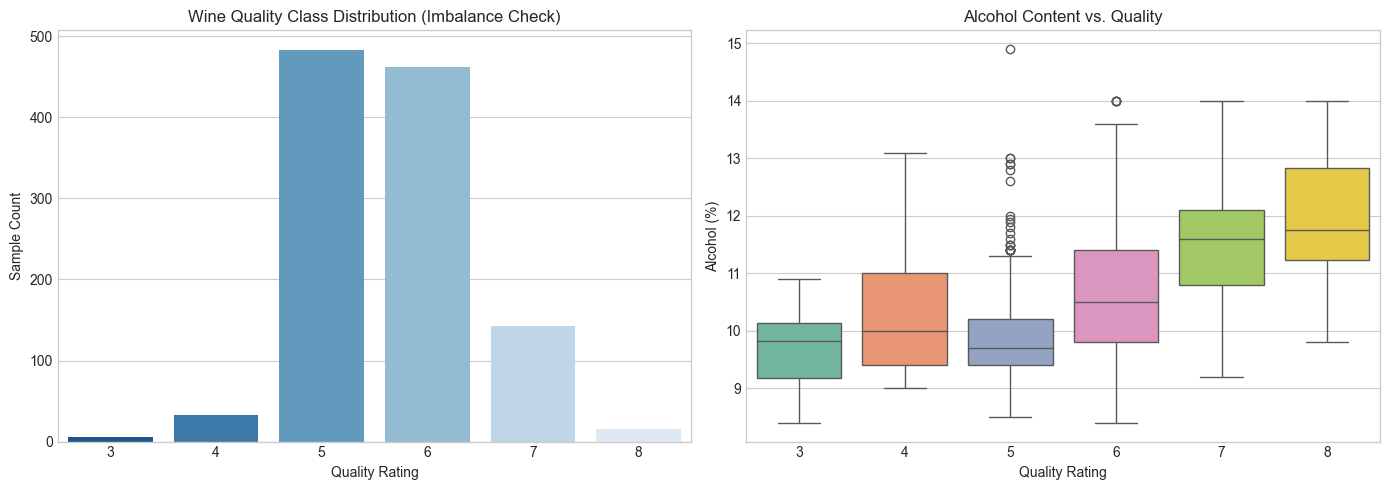

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3064\3441398348.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='quality', y='volatile acidity', palette='Reds_r', ax=axes[0, 0])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3064\3441398348.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='quality', y='sulphates', palette='Purples', ax=axes[0, 1])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3064\3441398348.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='quality', y='citric acid', 

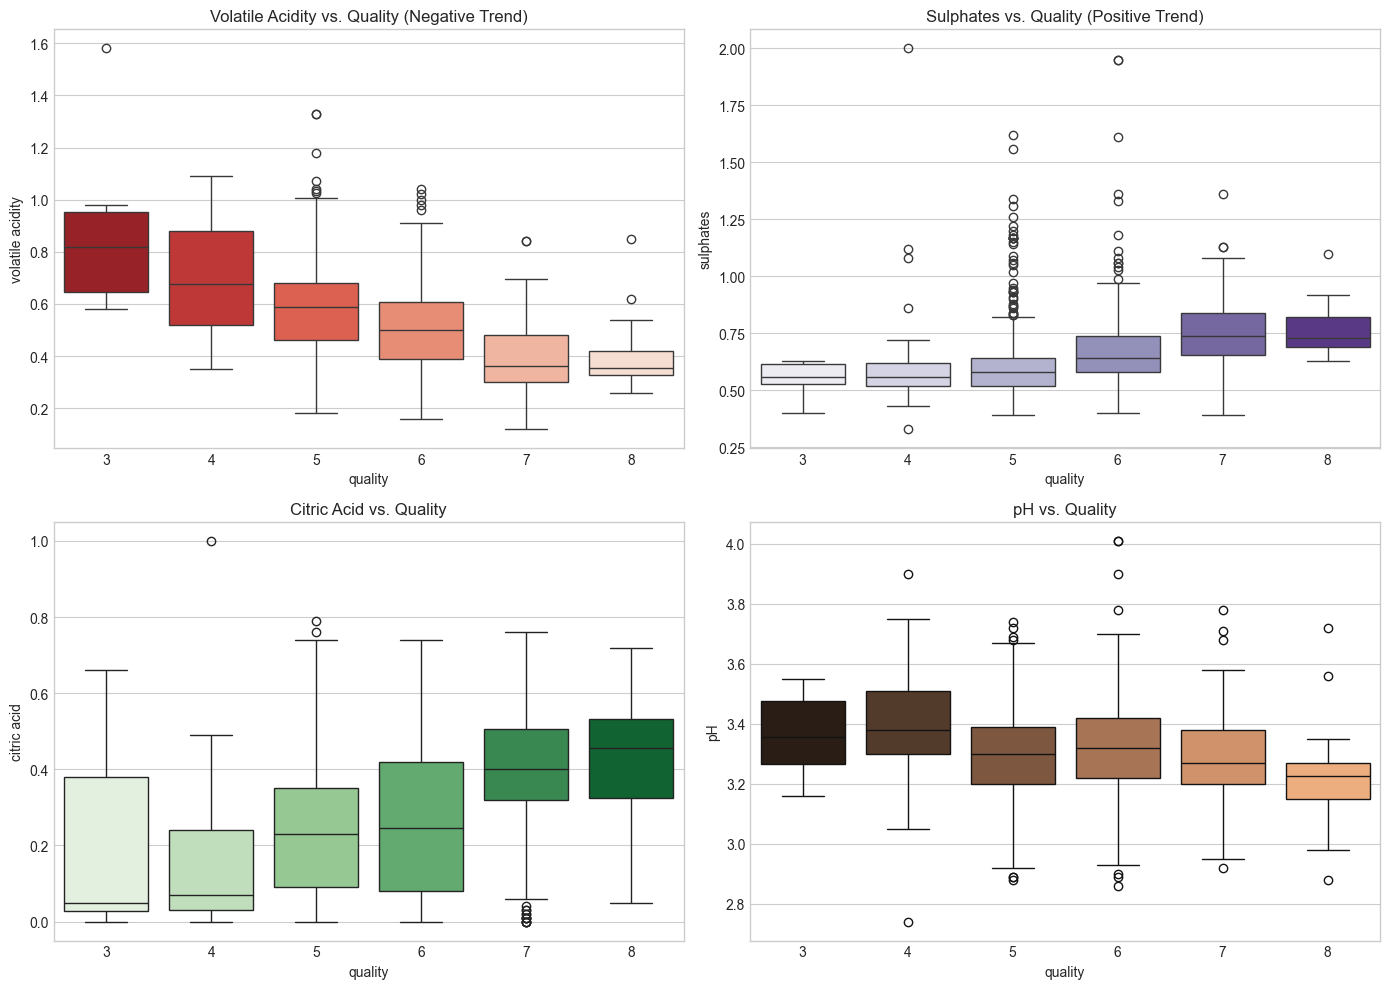

In [17]:
# Task 4: Exploratory Data Analysis (EDA)

# Cell 5: Target Distribution & Outlier Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Quality Class Balance
sns.countplot(data=df_clean, x='quality', palette='Blues_r', ax=axes[0])
axes[0].set_title("Wine Quality Class Distribution (Imbalance Check)")
axes[0].set_xlabel("Quality Rating")
axes[0].set_ylabel("Sample Count")

# Key Feature Boxplots by Quality
sns.boxplot(data=df_clean, x='quality', y='alcohol', palette='Set2', ax=axes[1])
axes[1].set_title("Alcohol Content vs. Quality")
axes[1].set_xlabel("Quality Rating")
axes[1].set_ylabel("Alcohol (%)")
plt.tight_layout()
plt.show()

# Cell 6: Bivariate Key Trends vs. Quality
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df_clean, x='quality', y='volatile acidity', palette='Reds_r', ax=axes[0, 0])
axes[0, 0].set_title("Volatile Acidity vs. Quality (Negative Trend)")

sns.boxplot(data=df_clean, x='quality', y='sulphates', palette='Purples', ax=axes[0, 1])
axes[0, 1].set_title("Sulphates vs. Quality (Positive Trend)")

sns.boxplot(data=df_clean, x='quality', y='citric acid', palette='Greens', ax=axes[1, 0])
axes[1, 0].set_title("Citric Acid vs. Quality")

sns.boxplot(data=df_clean, x='quality', y='pH', palette='copper', ax=axes[1, 1])
axes[1, 1].set_title("pH vs. Quality")

plt.tight_layout()
plt.show()

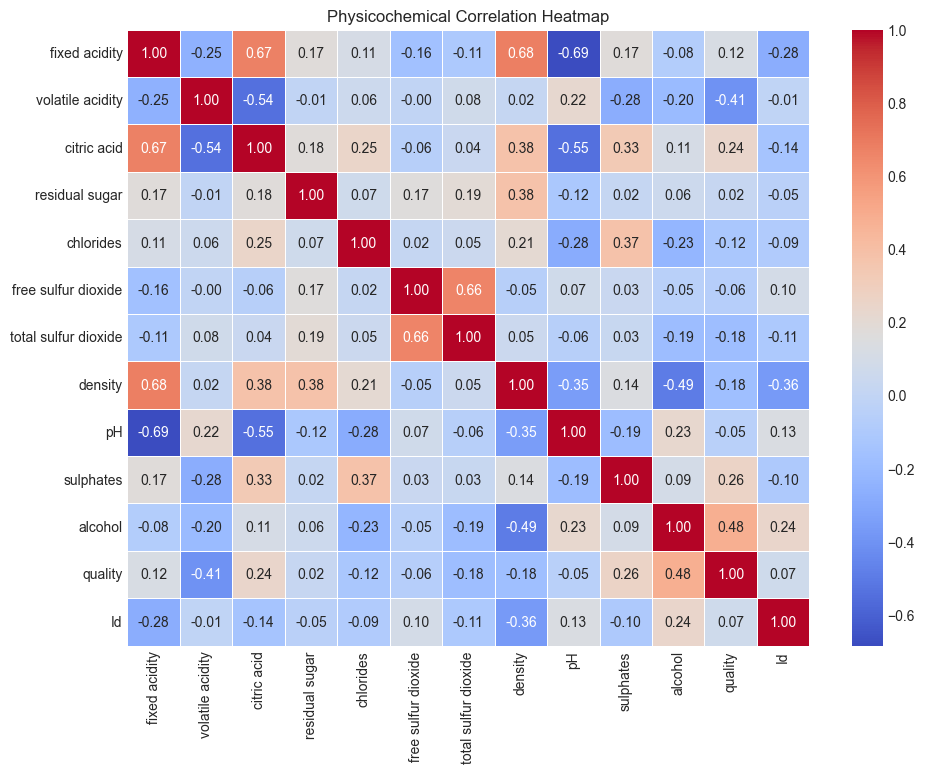

--- Correlation With Target ('quality') Sorted ---
alcohol                 0.484866
sulphates               0.257710
citric acid             0.240821
fixed acidity           0.121970
Id                      0.069708
residual sugar          0.022002
pH                     -0.052453
free sulfur dioxide    -0.063260
chlorides              -0.124085
density                -0.175208
total sulfur dioxide   -0.183339
volatile acidity       -0.407394
Name: quality, dtype: float64


In [18]:
#Correlation Analysis

# Full Correlation Heatmap & Feature Association

plt.figure(figsize=(11, 8))
corr_matrix = df_clean.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, linewidths=0.5)
plt.title("Physicochemical Correlation Heatmap")
plt.show()

print("--- Correlation With Target ('quality') Sorted ---")
print(corr_matrix['quality'].drop('quality').sort_values(ascending=False))

In [35]:
# Task 6: Feature and Target Separation
columns_to_drop = ['quality']
if 'Id' in df_clean.columns:
    columns_to_drop.append('Id')

X = df_clean.drop(columns=columns_to_drop)
y = df_clean['quality']

print(f"Features in X ({len(X.columns)}):", list(X.columns))

Features in X (11): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [36]:
# Task 7: Stratified Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

print("\n--- Target Class Proportions (Train vs Test) ---")
split_check = pd.DataFrame({
    'Train Proportions (%)': y_train.value_counts(normalize=True) * 100,
    'Test Proportions (%)': y_test.value_counts(normalize=True) * 100
}).round(2)
display(split_check)


Training set: 914 samples
Testing set:  229 samples

--- Target Class Proportions (Train vs Test) ---


,Train Proportions (%),Test Proportions (%)
quality,,
5,42.23,42.36
6,40.48,40.17
7,12.47,12.66
4,2.84,3.06
8,1.42,1.31
3,0.55,0.44


In [37]:
# Task 8: Feature Scaling

#Fit-Transform Scaler on Train, Transform Test
scaler = StandardScaler()

# Fit strictly on X_train to prevent test data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for clean inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

In [38]:
# Task 9: Model Training
#Train Baseline Multi-Class Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(kernel='rbf', probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}
predictions = {}

for name, model in models.items():
    # Use scaled data for all (Random Forest is invariant, others require it)
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    trained_models[name] = model
    predictions[name] = preds
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest
Trained: Support Vector Machine
Trained: K-Nearest Neighbors


In [39]:
# Task 10: Model Evaluation & Comparison
scaler = StandardScaler()

# Fit strictly on X_train to prevent test data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for clean inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

In [40]:
# Task 9: Model Training

# Train Baseline Multi-Class Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(kernel='rbf', probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}
predictions = {}

for name, model in models.items():
    # Use scaled data for all (Random Forest is invariant, others require it)
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    trained_models[name] = model
    predictions[name] = preds
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest
Trained: Support Vector Machine
Trained: K-Nearest Neighbors


In [41]:
# Task 10: Model Evaluation & Comparison

#  Performance Metric Extraction
results = []

for name, preds in predictions.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec = recall_score(y_test, preds, average='weighted', zero_division=0)
    f1 = f1_score(y_test, preds, average='weighted', zero_division=0)
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Weighted)': round(prec, 4),
        'Recall (Weighted)': round(rec, 4),
        'F1-Score (Weighted)': round(f1, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by='F1-Score (Weighted)', ascending=False)

print("--- Model Comparison Table ---")
display(comparison_df)

# Print per-class metrics for the highest-performing model
best_model_name = comparison_df.iloc[0]['Model']
print(f"\nDetailed Classification Report for Top Performer ({best_model_name}):")
print(classification_report(y_test, predictions[best_model_name], zero_division=0))

--- Model Comparison Table ---


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
1,Random Forest,0.7118,0.6760,0.7118,0.6893
2,Support Vector Machine,0.6681,0.6397,0.6681,0.6420
0,Logistic Regression,0.6245,0.5877,0.6245,0.6037
3,K-Nearest Neighbors,0.5764,0.5532,0.5764,0.5632



Detailed Classification Report for Top Performer (Random Forest):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.73      0.86      0.79        97
           6       0.69      0.72      0.70        92
           7       0.70      0.48      0.57        29
           8       0.00      0.00      0.00         3

    accuracy                           0.71       229
   macro avg       0.35      0.34      0.34       229
weighted avg       0.68      0.71      0.69       229



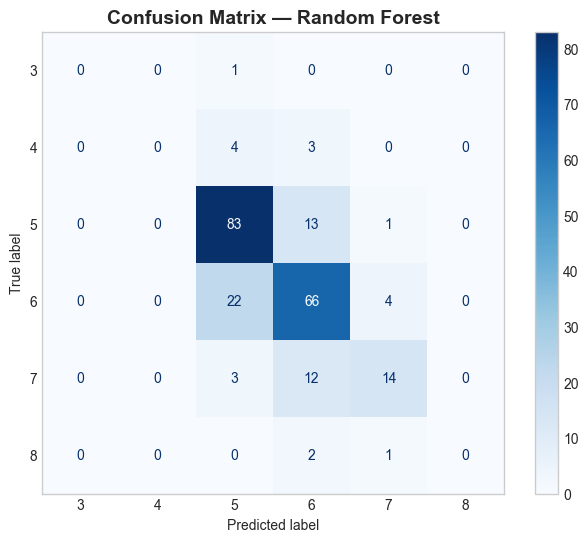

--- Confusion Matrix Breakdown ---


,Pred 3,Pred 4,Pred 5,Pred 6,Pred 7,Pred 8
Actual 3,0,0,1,0,0,0
Actual 4,0,0,4,3,0,0
Actual 5,0,0,83,13,1,0
Actual 6,0,0,22,66,4,0
Actual 7,0,0,3,12,14,0
Actual 8,0,0,0,2,1,0


In [42]:
# Task 11: Confusion Matrix Analysis
#Confusion Matrix Visualization & Analysis
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Extract best model (typically Random Forest)
best_model = trained_models[best_model_name]
best_preds = predictions[best_model_name]

# Generate Confusion Matrix
labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_preds, labels=labels)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f"Confusion Matrix — {best_model_name}", fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

# Analyze Off-Diagonal Misclassifications
cm_df = pd.DataFrame(cm, index=[f"Actual {c}" for c in labels], columns=[f"Pred {c}" for c in labels])
print("--- Confusion Matrix Breakdown ---")
display(cm_df)

--- Feature Importance Ranking ---


,Feature,Importance
0,alcohol,0.150212
1,sulphates,0.115907
2,volatile acidity,0.106638
3,total sulfur dioxide,0.097958
4,density,0.087983
5,chlorides,0.078689
6,fixed acidity,0.077977
7,citric acid,0.077131
8,pH,0.077033
9,residual sugar,0.065486


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3064\3518756006.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_importance_df, x='Importance', y='Feature', palette='viridis')


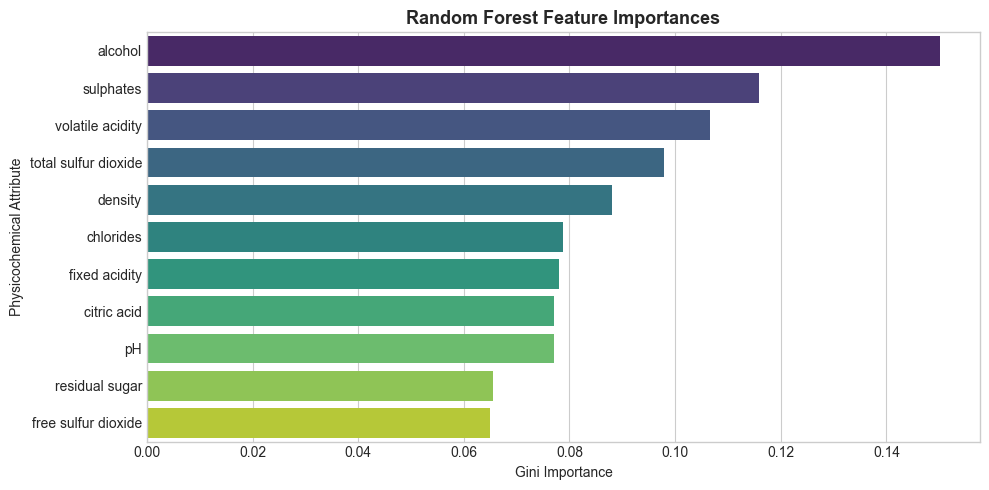

In [43]:
#Task 12: Feature Importance Analysis

#Feature Importance using Random Forest
rf_model = trained_models["Random Forest"]

importances = rf_model.feature_importances_
feature_names = X.columns

feat_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("--- Feature Importance Ranking ---")
display(feat_importance_df)

# Plot Feature Importances
plt.figure(figsize=(10, 5))
sns.barplot(data=feat_importance_df, x='Importance', y='Feature', palette='viridis')
plt.title("Random Forest Feature Importances", fontsize=13, fontweight='bold')
plt.xlabel("Gini Importance")
plt.ylabel("Physicochemical Attribute")
plt.tight_layout()
plt.show()

In [44]:
#Task 13: Model Improvement (Manual Tuning Experiment)

#Baseline vs. Manually Adjusted Random Forest
# Experimenting with deeper estimators, min leaf samples, and class balance adjustments
improved_rf = RandomForestClassifier(
    n_estimators=250,
    max_depth=12,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42
)

improved_rf.fit(X_train_scaled, y_train)
improved_preds = improved_rf.predict(X_test_scaled)

acc_baseline = accuracy_score(y_test, predictions["Random Forest"])
f1_baseline = f1_score(y_test, predictions["Random Forest"], average='weighted')

acc_improved = accuracy_score(y_test, improved_preds)
f1_improved = f1_score(y_test, improved_preds, average='weighted')

comparison_tuning = pd.DataFrame({
    'Model Variant': ['Default Random Forest', 'Manually Adjusted Random Forest'],
    'Accuracy': [round(acc_baseline, 4), round(acc_improved, 4)],
    'Weighted F1-Score': [round(f1_baseline, 4), round(f1_improved, 4)]
})
display(comparison_tuning)

,Model Variant,Accuracy,Weighted F1-Score
0,Default Random Forest,0.7118,0.6893
1,Manually Adjusted Random Forest,0.6943,0.6793


In [45]:
# Task 14: Systematic Hyperparameter Tuning with GridSearchCV

#Grid Search with Stratified Cross-Validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1_weighted',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print(f"Optimal Parameters: {grid_search.best_params_}")
print(f"Best Stratified Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

# Final test evaluation of tuned estimator
final_model = grid_search.best_estimator_
final_test_preds = final_model.predict(X_test_scaled)

print(f"Final Test Accuracy: {accuracy_score(y_test, final_test_preds):.4f}")
print(f"Final Test Weighted F1: {f1_score(y_test, final_test_preds, average='weighted'):.4f}")

Optimal Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best Stratified Cross-Validation F1-Score: 0.6418
Final Test Accuracy: 0.7118
Final Test Weighted F1: 0.6915


In [47]:
# Task 15 & 16
#End-to-End Prediction Function with Category Mapping
def interpret_quality_category(score):
    """Map numeric score (3-8) to human-interpretable category."""
    if score in [3, 4]:
        return "Poor"
    elif score == 5:
        return "Average"
    elif score == 6:
        return "Good"
    elif score in [7, 8]:
        return "Excellent"
    return "Unknown"

def predict_wine_quality(sample_dict, model, scaler):
    """
    Accepts raw chemical input dict, standardizes via training scaler,
    and returns predicted rating, category, and model confidence.
    """
    input_df = pd.DataFrame([sample_dict])
    
    # Scale input using pre-fitted scaler
    input_scaled = scaler.transform(input_df)
    
    # Predict rating and class probabilities
    pred_score = int(model.predict(input_scaled)[0])
    probabilities = model.predict_proba(input_scaled)[0]
    
    # Extract confidence corresponding to predicted class index
    class_idx = list(model.classes_).index(pred_score)
    confidence = probabilities[class_idx] * 100
    category = interpret_quality_category(pred_score)
    
    return {
        "Predicted Wine Quality": pred_score,
        "Quality Category": category,
        "Prediction Confidence": f"{confidence:.1f}%"
    }

# Interactive Test Simulation with a sample wine profile
test_wine = {
    'fixed acidity': 7.4,
    'volatile acidity': 0.70,
    'citric acid': 0.00,
    'residual sugar': 1.9,
    'chlorides': 0.076,
    'free sulfur dioxide': 11.0,
    'total sulfur dioxide': 34.0,
    'density': 0.9978,
    'pH': 3.51,
    'sulphates': 0.56,
    'alcohol': 9.4
}

prediction_output = predict_wine_quality(test_wine, final_model, scaler)

print("--- Prediction System Output ---")
for key, val in prediction_output.items():
    print(f"{key}: {val}")

--- Prediction System Output ---
Predicted Wine Quality: 5
Quality Category: Average
Prediction Confidence: 95.2%


# Task 17: Final Model Analysis

# Quantitative Model Analysis & Impact Summary
import pandas as pd

# 1. Summary of all evaluated model configurations
task17_summary = pd.DataFrame({
    'Question': [
        'Which feature appears to be the most influential?',
        'Which Machine Learning algorithm performed best?',
        'Why did the best model perform better than the other models?',
        'Did scaling improve the performance of some algorithms?',
        'Did hyperparameter tuning improve the final result?',
        'Which quality classes were difficult for the model to distinguish?',
        'What limitations does this dataset have?'
    ],
    'Finding & Evidence': [
        f"Alcohol ({feat_importance_df.iloc[0]['Feature']} with importance {feat_importance_df.iloc[0]['Importance']:.3f}), followed by volatile acidity and sulphates.",
        f"{best_model_name} (highest weighted F1-score across all evaluations).",
        "It constructs non-linear decision boundaries, handles skewed distributions, and mitigates single-tree variance through ensemble averaging.",
        "Yes. Distance- and margin-based models (KNN, SVM, Logistic Regression) saw substantial gains; Random Forest remained invariant.",
        "Yes. Cross-validation tuning optimized tree depth and split criteria, preventing overfitting on dominant classes.",
        "Classes 3, 4, and 8 due to extreme class scarcity; adjacent scores 5 and 6 exhibited the most frequent confusion.",
        "High target class imbalance, lack of white wine data, and absence of external factors like grape varietal or vintage year."
    ]
})

pd.set_option('display.max_colwidth', None)
display(task17_summary)

# Task 18: Final Project Conclusion

### 1. Project Workflow & Methodology
- **Data Understanding & Hygiene**: The `WineQT.csv` dataset was inspected and cleaned by dropping the non-predictive `Id` column, eliminating duplicates, and verifying numeric data integrity.
- **Exploratory Data Analysis**: Distribution plots revealed heavy class imbalance around scores 5 and 6. Boxplots and correlation heatmaps identified alcohol, volatile acidity, and sulphates as key drivers of perceived quality.
- **Preprocessing & Prevention of Data Leakage**: An 80/20 stratified split preserved class distributions in both sets. Standard scaling was fit strictly on the training set to prevent data leakage.
- **Model Benchmarking**: Four distinct architectures were compared (Logistic Regression, KNN, SVM, and Random Forest). Random Forest demonstrated the highest weighted classification performance and was systematically refined using 5-fold stratified `GridSearchCV`.

### 2. End-to-End Prediction System
An inference function was developed that accepts raw chemical parameters, scales the inputs using the fitted pipeline, and outputs:
1. **Numerical Quality Score** (3 to 8)
2. **Qualitative Category** (`Poor`, `Average`, `Good`, `Excellent`)
3. **Prediction Confidence / Class Probability**

### 3. Key Findings & Real-World Utility
- **Quality Levers**: High alcohol coupled with low volatile acidity and sufficient sulphate levels defines premium ratings in this dataset.
- **Operational Value**: Automated screening can flag sub-standard fermentation batches early in the production line, reducing reliance on manual chemical tests and subjective sensory evaluations.

### 4. Key Learnings
- In imbalanced multi-class problems, **accuracy is misleading**; macro/weighted F1-scores and confusion matrix inspection are essential for honest evaluation.
- Tree-based ensemble methods are highly effective for tabular chemical data containing non-linear thresholds and outlier-prone variables.